Dataset: downloading Dhaka road network from OpenStreetMap ...
Graph: 7,344 intersections, 17,995 directed road segments

Running 60 start/goal pairs x 3 algorithms ...
Check passed: A* matches UCS optimal cost on every pair.

=============== SUMMARY ===============
               Success_pct  Optimal_pct  Mean_Cost_m  Mean_Subopt_pct  Mean_Expanded  Median_Expanded  Mean_Time_ms
Algorithm                                                                                                          
UCS                  100.0        100.0      5768.85              0.0        4461.88           4475.0          9.53
A*                   100.0        100.0      5768.85              0.0        1251.67            847.5          3.93
Hill Climbing          0.0          0.0          NaN              NaN          11.20              6.5          0.51 



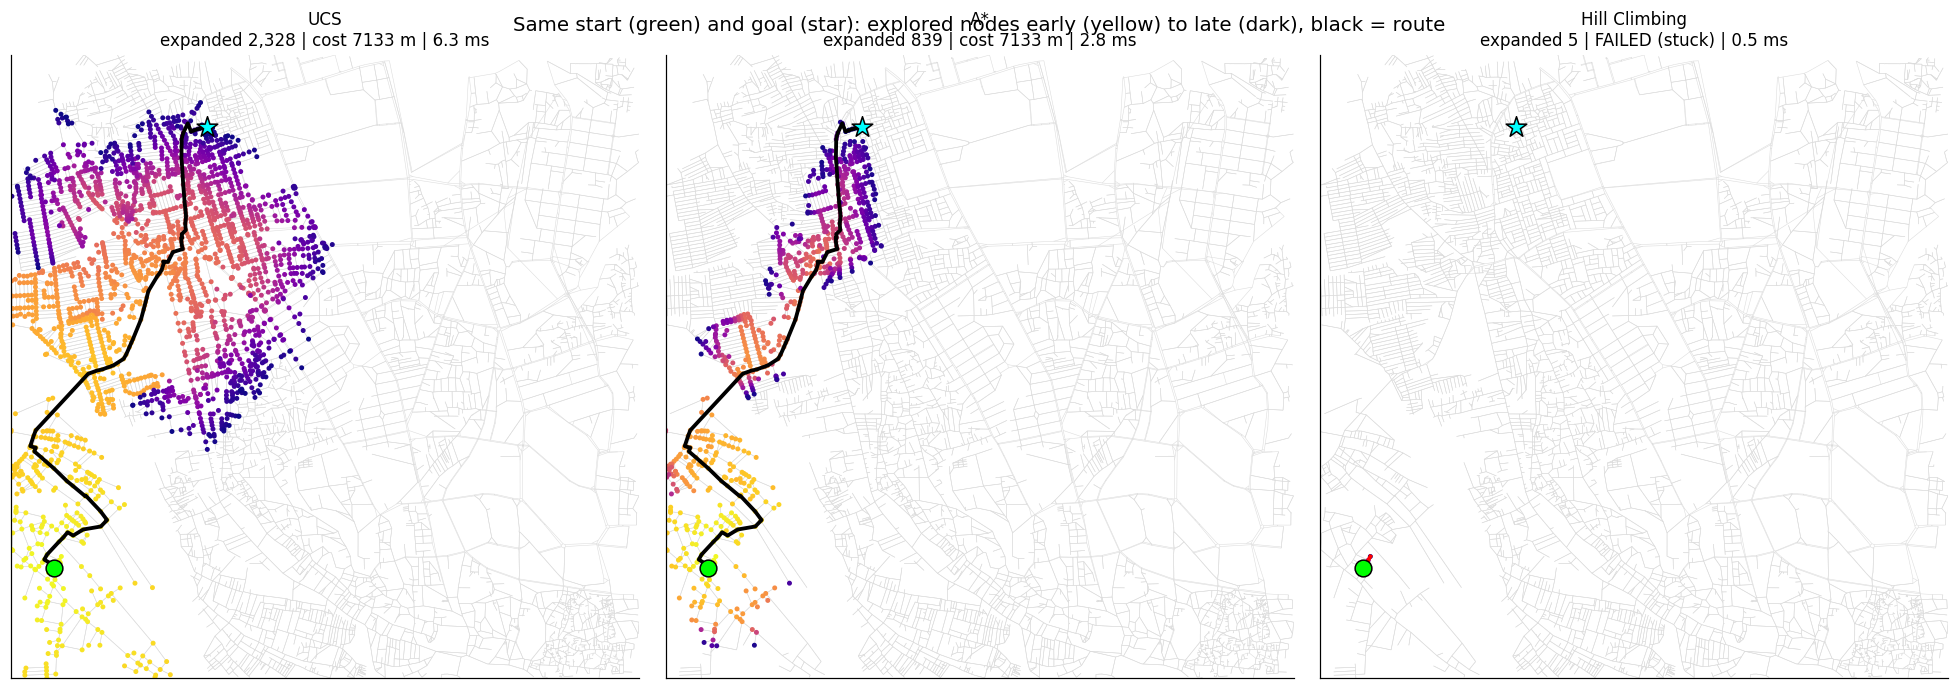

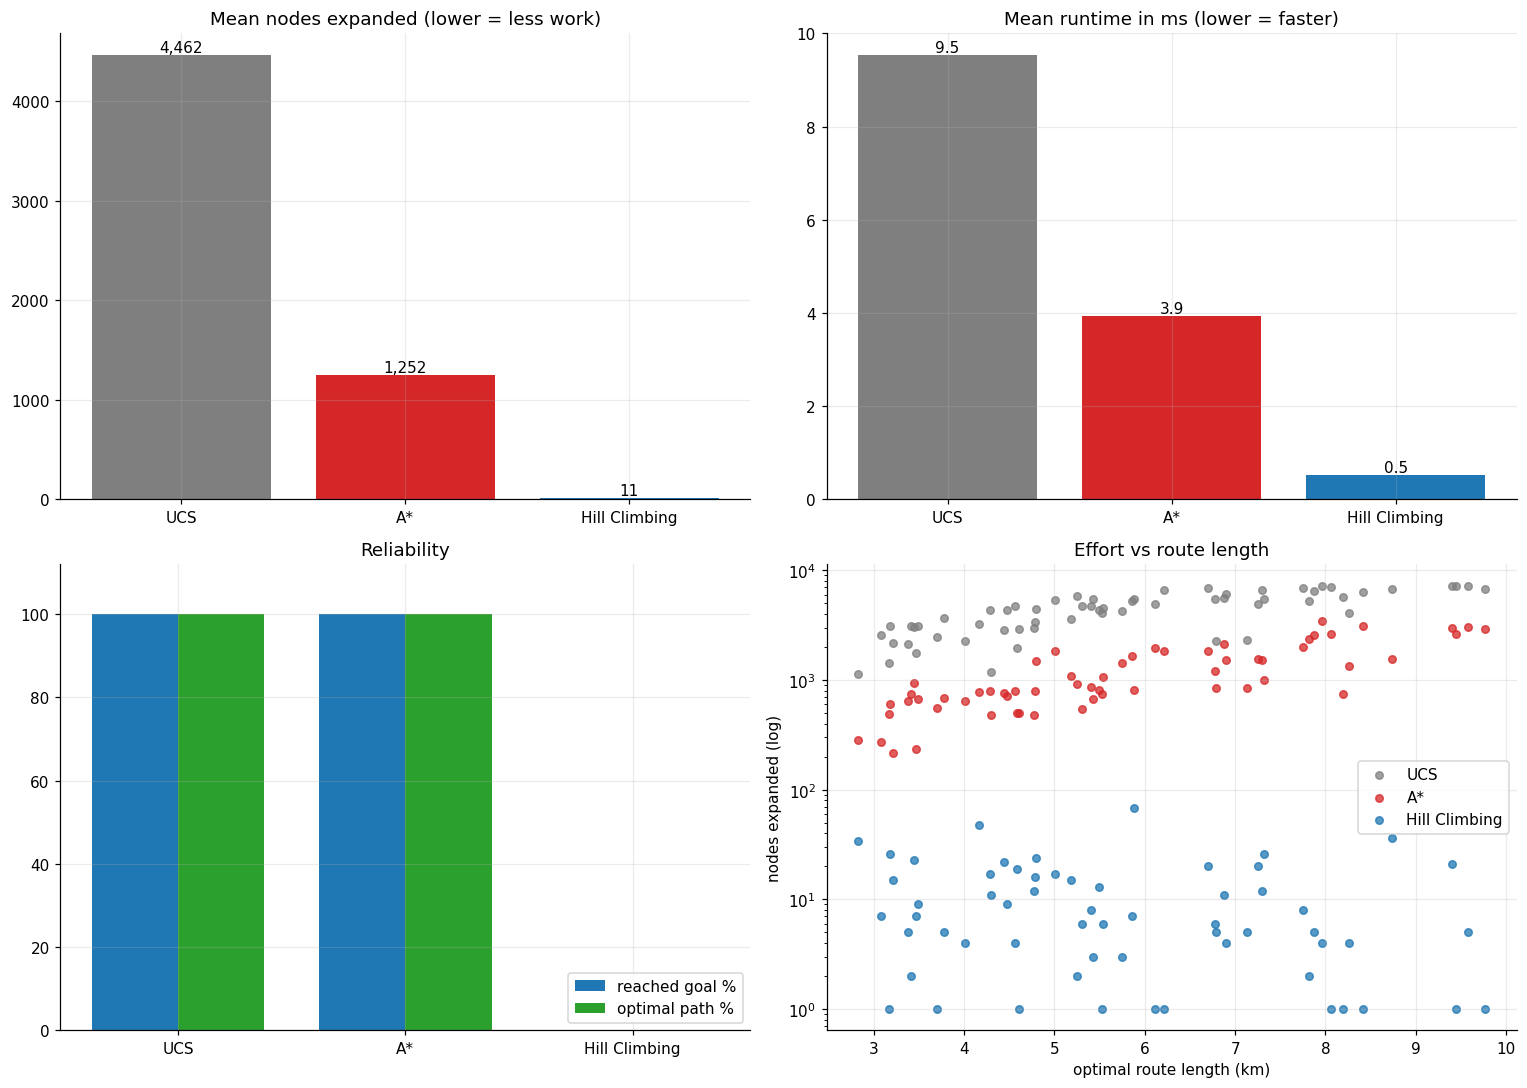

=============== CONCLUSION ===============
UCS           : optimal in 100% of runs, but expands the most nodes (4,462 on average).
A*            : optimal in 100% of runs with 71.9% fewer expansions than UCS (1,252).
Hill Climbing : smallest search (11 nodes) but reaches the goal in only 0% of runs and is optimal in 0%.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
# AIL Project
# UCS vs A* vs Hill Climbing on the Dhaka road network (single Colab cell)
!pip install -q osmnx

import os, math, time, heapq, random, shutil, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection



CENTER     = (23.7461, 90.3742)
RADIUS_M   = 3500
GRAPH_FILE = "dhaka_street_network.graphml"
N_PAIRS    = 60
MIN_SPAN   = 0.30
SEED       = 42
OUT        = "results"
ALGOS      = ["UCS", "A*", "Hill Climbing"]
COLORS     = {"UCS": "#7f7f7f", "A*": "#d62728", "Hill Climbing": "#1f77b4"}

random.seed(SEED); np.random.seed(SEED); os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})


def hav_m(lat1, lon1, lat2, lon2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 2 * 6371000.0 * math.asin(math.sqrt(min(1, a)))


def to_digraph(G0):
    directed = G0.is_directed(); D = nx.DiGraph()
    for n, d in G0.nodes(data=True):
        D.add_node(str(n), x=float(d["x"]), y=float(d["y"]))
    for u, v, d in G0.edges(data=True):
        u, v = str(u), str(v)
        try: L = float(d.get("length"))
        except (TypeError, ValueError): continue
        if u == v or not math.isfinite(L): continue
        L = max(L, 1e-3)
        for a, b in ([(u, v)] if directed else [(u, v), (v, u)]):
            if D.has_edge(a, b): D[a][b]["length"] = min(D[a][b]["length"], L)
            else: D.add_edge(a, b, length=L)
    return D.subgraph(max(nx.strongly_connected_components(D), key=len)).copy()


def synthetic_city(n=45):
    # Fallback when OpenStreetMap is unreachable: jittered grid with missing roads
    G = nx.Graph(); rng = np.random.default_rng(SEED)
    for i in range(n):
        for j in range(n):
            G.add_node(i * n + j, x=CENTER[1] + (j + rng.normal(0, .18)) * 0.0007,
                       y=CENTER[0] + (i + rng.normal(0, .18)) * 0.0007)
    for i in range(n):
        for j in range(n):
            for di, dj in ((0, 1), (1, 0)):
                a, b = i * n + j, (i + di) * n + (j + dj)
                if i + di < n and j + dj < n and rng.random() > 0.15:
                    pa, pb = G.nodes[a], G.nodes[b]
                    G.add_edge(a, b, length=hav_m(pa["y"], pa["x"], pb["y"], pb["x"]) * rng.uniform(1.0, 1.4))
    return G


def load_dataset():
    if os.path.exists(GRAPH_FILE):
        print(f"Dataset: local file {GRAPH_FILE}")
        return to_digraph(nx.read_graphml(GRAPH_FILE))
    try:
        import osmnx as ox
        print("Dataset: downloading Dhaka road network from OpenStreetMap ...")
        return to_digraph(ox.graph_from_point(CENTER, dist=RADIUS_M, network_type="drive", simplify=True))
    except Exception as e:
        print(f"Dataset: OSM unavailable ({type(e).__name__}); using synthetic road network")
        return to_digraph(synthetic_city())


G = load_dataset()
nodes = list(G.nodes()); idx = {n: i for i, n in enumerate(nodes)}; N = len(nodes)
lon = np.array([G.nodes[n]["x"] for n in nodes]); lat = np.array([G.nodes[n]["y"] for n in nodes])
lat_r, lon_r = np.radians(lat), np.radians(lon)
X = (lon - lon.mean()) * 111.320 * math.cos(math.radians(lat.mean()))
Y = (lat - lat.mean()) * 110.540
adj = [[] for _ in range(N)]
for u, v, d in G.edges(data=True): adj[idx[u]].append((idx[v], d["length"]))
print(f"Graph: {N:,} intersections, {G.number_of_edges():,} directed road segments\n")


def hav_to(t):
    a = np.sin((lat_r - lat_r[t]) / 2) ** 2 + np.cos(lat_r) * np.cos(lat_r[t]) * np.sin((lon_r - lon_r[t]) / 2) ** 2
    return 2 * 6371000.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def best_first(s, t, h):
    # Shared engine: priority = g + h. h = 0 gives UCS; h = Haversine gives A*
    g = {s: 0.0}; parent = {s: -1}; pq = [(h[s], 0.0, s)]; order = []
    while pq:
        _, gc, u = heapq.heappop(pq)
        if gc > g[u] + 1e-9: continue
        order.append(u)
        if u == t: break
        for v, w in adj[u]:
            ng = gc + w
            if ng < g.get(v, math.inf):
                g[v] = ng; parent[v] = u; heapq.heappush(pq, (ng + h[v], ng, v))
    if t not in g: return dict(ok=False, cost=np.nan, path=[s], order=order)
    path, c = [], t
    while c != -1: path.append(c); c = parent[c]
    return dict(ok=True, cost=g[t], path=path[::-1], order=order)


def ucs(s, t):    return best_first(s, t, [0.0] * N)
def a_star(s, t): return best_first(s, t, hav_to(t).tolist())


def hill_climb(s, t, max_steps=20000):
    # Steepest descent on straight-line distance; stops at a dead end / local minimum
    h = hav_to(t); cur, path, cost = s, [s], 0.0
    while cur != t and len(path) < max_steps:
        best, bh, bw = None, h[cur], 0.0
        for v, w in adj[cur]:
            if h[v] < bh: best, bh, bw = v, h[v], w
        if best is None: break
        cur = best; cost += bw; path.append(cur)
    ok = cur == t
    return dict(ok=ok, cost=cost if ok else np.nan, path=path, order=list(path))


FUNCS = {"UCS": ucs, "A*": a_star, "Hill Climbing": hill_climb}


def run(name, s, t):
    t0 = time.perf_counter(); r = FUNCS[name](s, t)
    r["ms"] = (time.perf_counter() - t0) * 1000; r["expanded"] = len(r["order"])
    return r


span = max(np.ptp(X), np.ptp(Y)) * 1000; pairs = []
while len(pairs) < N_PAIRS:
    a, b = np.random.randint(N, size=2)
    if a != b and hav_m(lat[a], lon[a], lat[b], lon[b]) > MIN_SPAN * span: pairs.append((int(a), int(b)))

print(f"Running {len(pairs)} start/goal pairs x {len(ALGOS)} algorithms ...")
rows, runs = [], {}
for pi, (s, t) in enumerate(pairs):
    res = {a: run(a, s, t) for a in ALGOS}; opt = res["UCS"]["cost"]
    for a in ALGOS:
        r = res[a]; runs[(pi, a)] = r
        rows.append(dict(Pair=pi, Algorithm=a, Route_km=opt / 1000, Success=r["ok"],
                         Optimal=bool(r["ok"] and abs(r["cost"] - opt) < 1.0), Cost_m=r["cost"],
                         Subopt_pct=(r["cost"] / opt - 1) * 100 if r["ok"] else np.nan,
                         Expanded=r["expanded"], Time_ms=r["ms"]))
df = pd.DataFrame(rows); df.to_csv(f"{OUT}/all_runs.csv", index=False)

# A* must match UCS exactly, otherwise the heuristic is not admissible
ucs_c = df[df.Algorithm == "UCS"].set_index("Pair").Cost_m
as_c = df[df.Algorithm == "A*"].set_index("Pair").Cost_m
assert np.allclose(ucs_c, as_c, atol=1.0), "A* cost differs from UCS"
print("Check passed: A* matches UCS optimal cost on every pair.\n")

summ = df.groupby("Algorithm").agg(
    Success_pct=("Success", lambda x: x.mean() * 100), Optimal_pct=("Optimal", lambda x: x.mean() * 100),
    Mean_Cost_m=("Cost_m", "mean"), Mean_Subopt_pct=("Subopt_pct", "mean"),
    Mean_Expanded=("Expanded", "mean"), Median_Expanded=("Expanded", "median"),
    Mean_Time_ms=("Time_ms", "mean")).reindex(ALGOS).round(2)
summ.to_csv(f"{OUT}/summary.csv")
print("=============== SUMMARY ===============")
print(summ.to_string(), "\n")

segs = [[(X[a], Y[a]), (X[b], Y[b])] for a in range(N) for b, _ in adj[a]]
s0, t0 = pairs[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.3))
for ax, a in zip(axes, ALGOS):
    r = runs[(0, a)]
    ax.add_collection(LineCollection(segs, colors="#dcdcdc", linewidths=0.35))
    o = np.array(r["order"]); ax.scatter(X[o], Y[o], c=np.arange(len(o)), cmap="plasma_r", s=5, zorder=2)
    p = np.array(r["path"]); ax.plot(X[p], Y[p], color="black" if r["ok"] else "red", lw=2.5, zorder=3)
    ax.scatter(X[s0], Y[s0], c="lime", s=120, edgecolor="k", zorder=5)
    ax.scatter(X[t0], Y[t0], c="cyan", s=200, edgecolor="k", marker="*", zorder=5)
    ax.set_xlim(X.min(), X.max()); ax.set_ylim(Y.min(), Y.max()); ax.set_aspect("equal")
    ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
    status = f"cost {r['cost']:.0f} m" if r["ok"] else "FAILED (stuck)"
    ax.set_title(f"{a}\nexpanded {r['expanded']:,} | {status} | {r['ms']:.1f} ms", fontsize=11)
fig.suptitle("Same start (green) and goal (star): explored nodes early (yellow) to late (dark), black = route", fontsize=13)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_search_maps.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for axis, col, title, fmt in [(ax[0, 0], "Mean_Expanded", "Mean nodes expanded (lower = less work)", "{:,.0f}"),
                              (ax[0, 1], "Mean_Time_ms", "Mean runtime in ms (lower = faster)", "{:.1f}")]:
    bars = axis.bar(ALGOS, summ[col].values, color=[COLORS[a] for a in ALGOS])
    axis.bar_label(bars, labels=[fmt.format(v) for v in summ[col].values]); axis.set_title(title)
x = np.arange(3); w = 0.38
ax[1, 0].bar(x - w / 2, summ["Success_pct"], w, label="reached goal %", color="#1f77b4")
ax[1, 0].bar(x + w / 2, summ["Optimal_pct"], w, label="optimal path %", color="#2ca02c")
ax[1, 0].set_xticks(x); ax[1, 0].set_xticklabels(ALGOS); ax[1, 0].set_ylim(0, 112)
ax[1, 0].legend(loc="lower right"); ax[1, 0].set_title("Reliability")
for a in ALGOS:
    d = df[df.Algorithm == a]; ax[1, 1].scatter(d.Route_km, d.Expanded, s=24, alpha=0.75, color=COLORS[a], label=a)
ax[1, 1].set_yscale("log"); ax[1, 1].set_xlabel("optimal route length (km)"); ax[1, 1].set_ylabel("nodes expanded (log)")
ax[1, 1].set_title("Effort vs route length"); ax[1, 1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig2_comparison_dashboard.png", bbox_inches="tight"); plt.show()

u, a_, h_ = summ.loc["UCS"], summ.loc["A*"], summ.loc["Hill Climbing"]
print("=============== CONCLUSION ===============")
print(f"UCS           : optimal in {u.Optimal_pct:.0f}% of runs, but expands the most nodes ({u.Mean_Expanded:,.0f} on average).")
print(f"A*            : optimal in {a_.Optimal_pct:.0f}% of runs with {100 * (1 - a_.Mean_Expanded / u.Mean_Expanded):.1f}% fewer expansions than UCS ({a_.Mean_Expanded:,.0f}).")
print(f"Hill Climbing : smallest search ({h_.Mean_Expanded:,.0f} nodes) but reaches the goal in only {h_.Success_pct:.0f}% of runs and is optimal in {h_.Optimal_pct:.0f}%.")

shutil.make_archive("results", "zip", OUT)
try:
    from google.colab import files; files.download("results.zip")
except Exception: pass